# hvo5 Part 2 and Part 3

Builds the monthly commit series, the 300 DPI plots, the longest-gap table, the commits on either side of that gap, and the per-project reflections from `hvo5_project_summary.csv`.

A month with no commits is still a row. The longest gap is the longest run of those months. `NumberOfGapsInTimeline` counts only runs of three months or more. GitHub stars, forks, and the last commit date are the figures recorded in `hvo5.ipynb` on 2026-09-28. Current status uses the assignment cutoff: Inactive only if the last commit is before 2025-04-01.

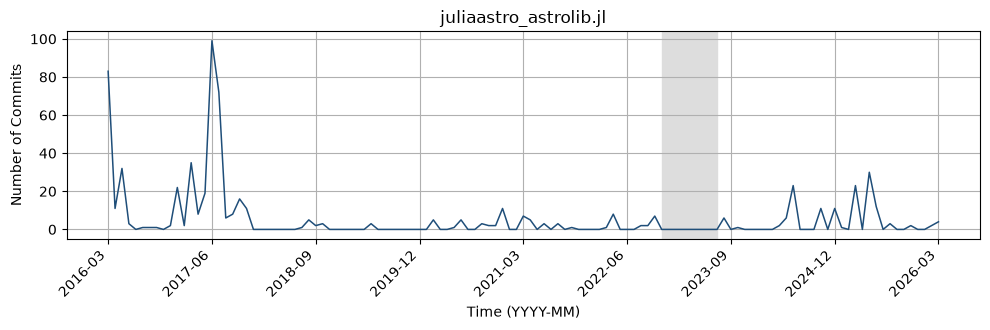

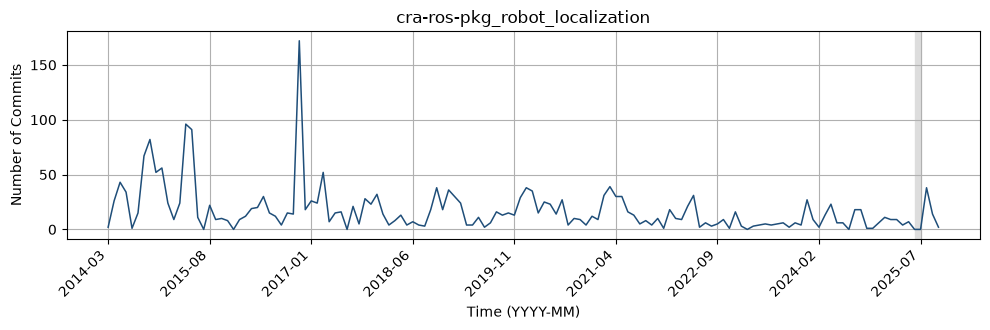

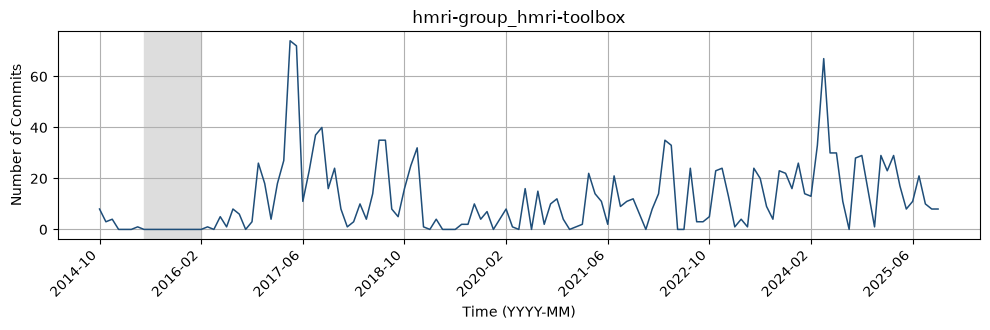

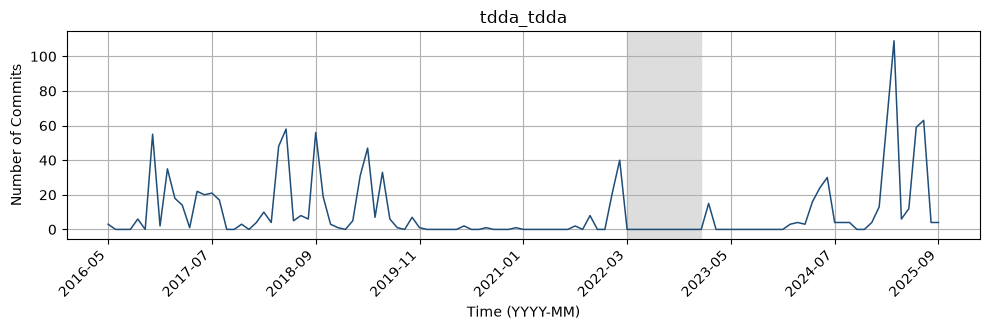

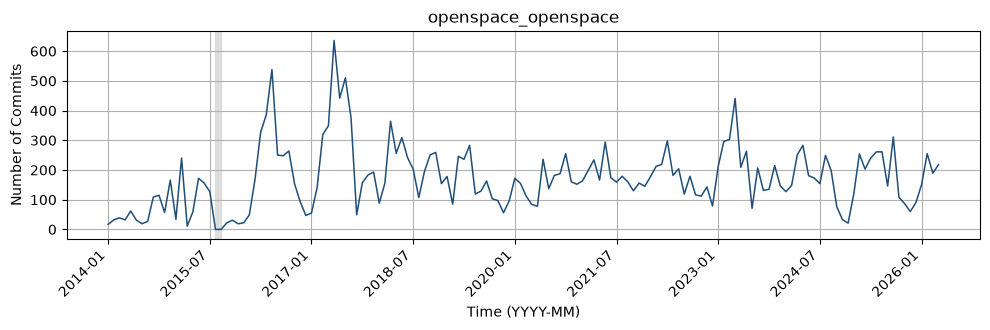

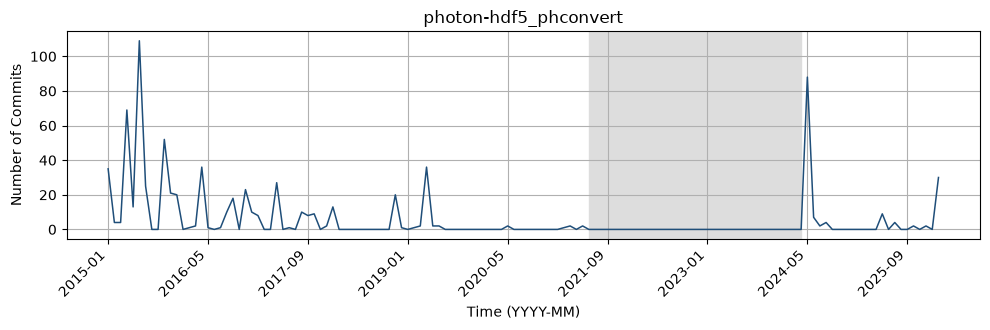

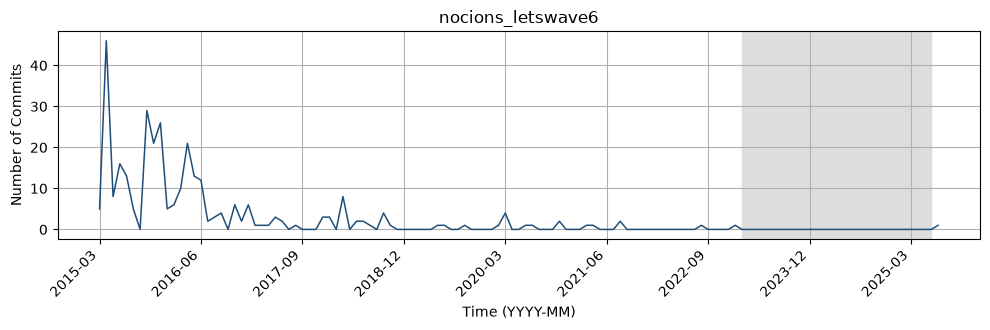

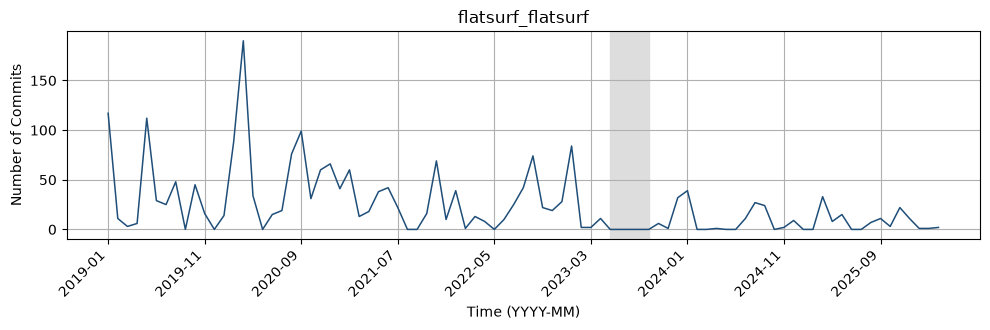

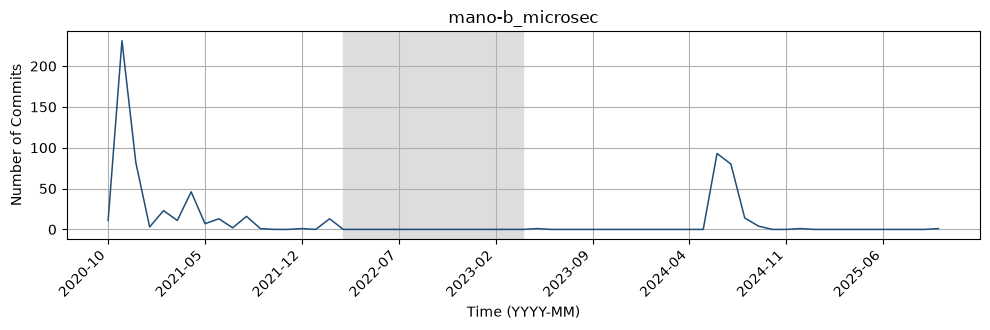

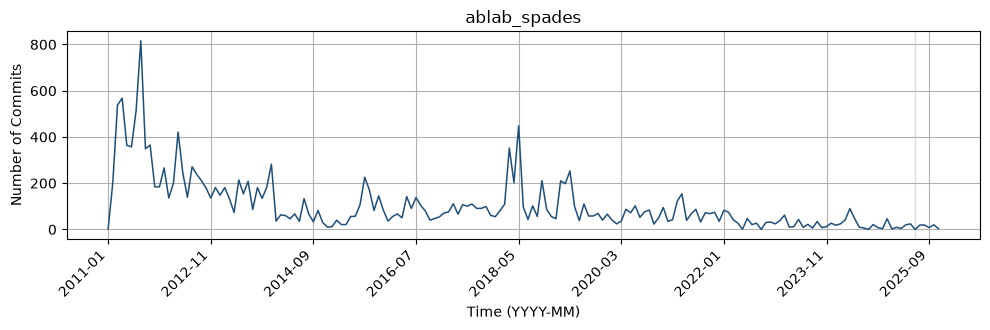

In [1]:
import matplotlib.pyplot as plt
import build_mp2 as bm

summary, results = bm.load()
bm.write_timeseries(results)
bm.write_gap_commits(summary, results)
bm.write_stats(results)
bm.write_reflections()

# The files are written at 300 DPI by write_timeseries. This cell redraws
# the same series so the shape is visible here. Title is the WoC project id.
for project in bm.ORDER:
    series = results[project]['series']
    labels = list(series.index)
    fig, ax = plt.subplots(figsize=(10, 3.4))
    ax.plot(range(len(series)), series.to_numpy(), color='#1f4e79', lw=1.1)
    start, end = results[project]['longest_start'], results[project]['longest_end']
    if start:
        ax.axvspan(labels.index(start), labels.index(end), color='#dddddd')
    step = max(len(labels) // 8, 1)
    ticks = list(range(0, len(labels), step))
    ax.set_xticks(ticks)
    ax.set_xticklabels([labels[i] for i in ticks], rotation=45, ha='right')
    ax.set_title(project)
    ax.set_xlabel('Time (YYYY-MM)')
    ax.set_ylabel('Number of Commits')
    ax.grid(True)
    fig.tight_layout()
    plt.show()


# Interpretation

The shaded band on each chart is the longest run of months with zero commits. Only three projects have no gap of three months or more, so for those the band is one or two months and there is no inactivity to explain.

- **ablab_spades** (0 gaps of 3+ months). Declining, from 4,442 commits in 2011 to 128 in 2025. The longest empty run is the single month 2025-06. A long decline is not a gap, and HasRecovered is No.
- **cra-ros-pkg_robot_localization** (0). Declining, from about 300-380 commits a year down to about 100. The longest empty run is two months in mid-2025. HasRecovered is No.
- **openspace_openspace** (0). Steady from 2016 on, between about 1,800 and 3,400 commits a year. The longest empty run is two months in 2015, during the move to a new SGCT. HasRecovered is No.
- **flatsurf_flatsurf** (1). Declining, from 692 commits in 2020 to about 110. The one real gap is five months in 2023, immediately after the 3.13.3 release, and Julian Rüth ends it with toolchain updates.
- **hmri-group_hmri-toolbox** (3). Irregular: 354 commits in 2017, 30 in 2019, 271 in 2024. The longest gap is ten months in 2015-2016 and is the move from the old VBQ branch into the shared repository.
- **mano-b_microsec** (3). U-shaped. 324 commits in 2020, 13 in 2022, 192 in 2024. The 14-month hole is ended by shibatay2301, a name that does not appear before it. The pre-gap messages are bare "Update file.R" lines, so they name no theme and no cause.
- **photon-hdf5_phconvert** (5). U-shaped, and the recovery is partial. 352 commits in 2015, two empty years, 101 in 2024. Paul Harris, new to the log, adds PTU types and moves the build to setuptools_scm.
- **tdda_tdda** (6). U-shaped, and the recovery passes the old peak: 222 in 2018, 4 in 2020, 331 in 2025. Nick Radcliffe, already a contributor, resumes at the 2.0 release.
- **juliaastro_astrolib.jl** (8). Declining from 298 in 2017 to the tens. The longest hole is nine months in 2022-2023. Henrik Wolf, new to the log, ends it, and 2024-2025 are busier without getting near 2017.
- **nocions_letswave6** (9). Declining from 169 in 2015 to empty in 2024. The longest hole is 29 months and only one commit follows it, André Mouraux adding a center-of-gravity amplitude. That is a recovery, and it is not the old project coming back.

Every project is Active. The latest GitHub commit on each one is after 2025-04-01. The reflections in `hvo5_reflection_<project>.md` go through the gap reason, who came back, and the latest themes for each project. `hvo5_project_stats.csv` is the single table.